# Workbook Day 2 — Bobathon ESILV (équipe jnr)

Réponses aux 17 questions du Day 2. Chaque question est suivie du code qui la calcule, puis de la réponse.

- Validation : GroupKFold à 5 plis sur `patient_id` (sauf l'étape 1-2 : `splitter=0.2` par défaut de skore).
- Tout tourne **en local** (pas de `put` sur le Hub) : les rapports Hub et les soumissions Kaggle se font dans Bob.
- Notre meilleur modèle hors workbook : `src/pipeline_ref.py`, **2.99** en CV groupée, **2.926** sur Kaggle public.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import skrub
from skore import evaluate
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from skrub import TableVectorizer, tabular_pipeline

warnings.filterwarnings("ignore")

X_train = pd.read_csv("X_train.csv")
y_train = pd.read_csv("y_train.csv")
X_test = pd.read_csv("X_test.csv")
visits = X_train.merge(y_train, on="Index")
y = visits["target"]

feature_cols = ["sexM", "age_at_diagnosis", "age", "ledd",
                "time_since_intake_on", "time_since_intake_off", "on", "off"]
X = visits[feature_cols]
dummy = DummyRegressor(strategy="mean")
print(visits.shape, "patients:", visits.patient_id.nunique(), "std target:", round(y.std(), 2))

(44590, 14) patients: 5576 std target: 16.5


## 1. Un modèle linéaire simple (Ridge)

In [2]:
ridge = make_pipeline(SimpleImputer(strategy="median"), Ridge(alpha=1.0))
report = evaluate({"dummy": dummy, "ridge": ridge}, X, y)
rmse_rand = report.metrics.summarize().frame().loc["rmse"]
rmse_rand

estimator
dummy    16.477937
ridge    10.487659
Name: rmse, dtype: float64

**Q1.1 — De combien de pourcents Ridge baisse-t-il le RMSE par rapport au dummy ? Gros ou petit gain ?**

16.48 → 10.49, soit **−36 %**. C'est un gros gain pour un modèle aussi simple : les variables numériques portent un vrai signal additif.

In [3]:
fitted = clone(ridge).fit(X, y)
scaled = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)).fit(X, y)
coefs = pd.DataFrame({"brut": fitted[-1].coef_, "standardisé": scaled[-1].coef_,
                      "écart-type de la variable": X.std()}, index=feature_cols)
coefs.reindex(coefs["brut"].abs().sort_values(ascending=False).index).round(3)

,brut,standardisé,écart-type de la variable
time_since_intake_on,1.704,1.490,1.169
age,1.073,12.373,11.536
age_at_diagnosis,-0.958,-10.119,10.854
off,0.590,7.708,17.177
on,0.478,4.363,10.862
sexM,-0.200,-0.098,0.490
time_since_intake_off,-0.155,-0.204,2.841
ledd,-0.000,-0.078,218.506


**Q1.2 — Quelle variable a le plus gros coefficient en valeur absolue ? Le signe de `off` et `on` est-il celui attendu cliniquement ?**

Le plus gros coefficient brut est `time_since_intake_on` (+1.70). `off` (+0.59) et `on` (+0.48) sont positifs, comme attendu : un score mesuré élevé annonce un vrai OFF élevé. `off` pèse plus car c'est la mesure directe de la cible, alors que `on` est atténué par le traitement. Le couple `age` (+1.07) / `age_at_diagnosis` (−0.96) revient à mesurer la durée de la maladie.

**Q1.3 — Les variables ne sont pas mises à l'échelle. Pourquoi ne peut-on pas lire « age compte plus que ledd » sur les coefficients bruts ?**

Un coefficient brut se lit « par unité » de sa variable, et les unités sont incomparables : l'écart-type de `ledd` vaut 219 mg, celui de `time_since_intake_on` 1.2 h. Une fois standardisées, le classement change : `age` (12.4) et `age_at_diagnosis` (−10.1) passent en tête, `time_since_intake_on` tombe à la 5e place (1.5).

## 2. Réglage d'alpha et soumission Kaggle

In [4]:
alphas = [0.01, 0.1, 1, 10, 100, 1_000, 10_000, 100_000]
rows = []
for a in alphas:
    pipe = make_pipeline(SimpleImputer(strategy="median"), Ridge(alpha=a))
    r = evaluate(pipe, X, y)
    coef = clone(pipe).fit(X, y)[-1].coef_
    rows.append({"alpha": a, "rmse": r.metrics.rmse(), **dict(zip(feature_cols, coef))})
alpha_table = pd.DataFrame(rows).set_index("alpha")
alpha_table.round(4)

,rmse,sexM,age_at_diagnosis,age,ledd,time_since_intake_on,time_since_intake_off,on,off
alpha,,,,,,,,,
0.01,10.4877,-0.1997,-0.9579,1.0730,-0.0005,1.7042,-0.1547,0.4776,0.5897
0.10,10.4877,-0.1997,-0.9579,1.0730,-0.0005,1.7042,-0.1547,0.4776,0.5897
1.00,10.4877,-0.1997,-0.9579,1.0730,-0.0005,1.7041,-0.1547,0.4776,0.5897
10.00,10.4877,-0.1995,-0.9579,1.0730,-0.0005,1.7037,-0.1547,0.4775,0.5897
100.00,10.4877,-0.1978,-0.9577,1.0728,-0.0005,1.6990,-0.1544,0.4774,0.5897
1000.00,10.4881,-0.1818,-0.9556,1.0710,-0.0004,1.6535,-0.1524,0.4764,0.5902
10000.00,10.4990,-0.0993,-0.9341,1.0522,-0.0001,1.3058,-0.1345,0.4681,0.5938
100000.00,10.6164,-0.0168,-0.7381,0.8745,0.0023,0.4296,-0.0612,0.4445,0.6063


**Q2.1 — Sur les alpha testés, de combien le RMSE bouge-t-il vraiment ? Pourquoi alpha compte-t-il si peu ici ?**

De 0.01 à 1 000, le RMSE ne bouge que de 0.0004 (10.4877 → 10.4881). Il ne se dégrade qu'à partir de 10 000 (10.62 à 100 000). La pénalité alpha × ‖w‖² est minuscule face à l'erreur sommée sur ~35 000 lignes, et avec 8 variables le modèle ne surapprend pas : il n'y a presque rien à régulariser.

**Q2.2 — Les coefficients ont-ils beaucoup changé entre le plus petit et le plus grand alpha ?**

Jusqu'à 1 000, ils sont quasi identiques (`time_since_intake_on` 1.70 → 1.65). À 100 000 ils se tassent vers zéro : `time_since_intake_on` tombe à 0.43, `sexM` de −0.20 à −0.02. `off` et `on` restent stables (0.61, 0.44) : leurs grandes échelles font que la pénalité les touche peu. On garde alpha = 1 pour `02_ridge`.

## 3. Validation croisée groupée par patient

In [5]:
groups = visits["patient_id"]
cv_splits = list(GroupKFold(n_splits=5).split(X, y, groups=groups))
report_cv = evaluate({"dummy": dummy, "ridge": ridge}, X, y, splitter=cv_splits)
cv_frame = report_cv.metrics.summarize().frame()
pd.DataFrame({"random split": rmse_rand.values,
              "grouped CV (moyenne)": cv_frame.loc["rmse"].filter(like="mean").values},
             index=["dummy", "ridge"]).round(3)

,random split,grouped CV (moyenne)
dummy,16.478,16.499
ridge,10.488,10.597


**Q3.1 — Comparer le RMSE en CV groupée avec le découpage aléatoire. Quel modèle a le plus changé ?**

Dummy : 16.48 → 16.50 (+0.02). Ridge : 10.49 → 10.60 (+0.11). **Ridge change le plus** : un modèle qui apprend profite de la fuite entre visites d'un même patient ; le dummy, qui n'apprend qu'une moyenne, n'en profite pas.

**Q3.2 — Quelle estimation est la plus proche du score Kaggle public ? Laquelle croire désormais ?**

Notre modèle fait **2.99 en CV groupée et 2.926 sur Kaggle public** : la CV groupée est très proche, car Kaggle met de côté des patients entiers, exactement comme GroupKFold. Le découpage aléatoire est trop optimiste. On ne se fie désormais qu'à la CV groupée.

## 4. HistGradientBoosting : les valeurs manquantes comme signal

In [6]:
def cv_scores(est, XX):
    """RMSE, fit and predict time per fold on cv_splits."""
    out = []
    for tr, te in cv_splits:
        e = clone(est)
        t0 = time.perf_counter(); e.fit(XX.iloc[tr], y.iloc[tr]); fit_t = time.perf_counter() - t0
        t0 = time.perf_counter(); p = e.predict(XX.iloc[te]); pred_t = time.perf_counter() - t0
        out.append({"rmse": root_mean_squared_error(y.iloc[te], p), "fit_s": fit_t, "predict_s": pred_t})
    return pd.DataFrame(out)

hgbr = HistGradientBoostingRegressor(random_state=0)
s_ridge, s_hgbr = cv_scores(ridge, X), cv_scores(hgbr, X)
s_hgbr_imputed = cv_scores(make_pipeline(SimpleImputer(strategy="median"),
                                         HistGradientBoostingRegressor(random_state=0)), X)
folds = pd.DataFrame({"ridge": s_ridge.rmse, "hgbr": s_hgbr.rmse, "hgbr NaN imputés": s_hgbr_imputed.rmse})
folds.index.name = "pli"
print(folds.round(3))
print(folds.agg(["mean", "std"]).round(3))
print("\ntemps moyens (s)\n", pd.DataFrame({"ridge": s_ridge.mean(), "hgbr": s_hgbr.mean()}).drop("rmse").round(4))

      ridge   hgbr  hgbr NaN imputés
pli                                 
0    10.663  7.824             7.882
1    11.018  7.936             7.999
2    10.446  7.576             7.619
3    10.320  7.617             7.623
4    10.535  7.824             7.852
       ridge   hgbr  hgbr NaN imputés
mean  10.597  7.756             7.795
std    0.267  0.153             0.168

temps moyens (s)
             ridge    hgbr
fit_s      0.0197  1.0623
predict_s  0.0014  0.0204


**Q4.1 — HGBR bat-il Ridge sur chaque pli, ou seulement en moyenne ?**

Sur **les 5 plis** : 7.76 ± 0.15 contre 10.60 ± 0.27 en moyenne. Le gain (~2.8 points) est 20 fois plus grand que l'écart entre plis.

Ablation : en remplaçant les NaN par la médiane, HGBR passe à 7.80. Garder les trous aide, un peu (~0.04).

**Q4.2 — Comparer les temps d'entraînement et de prédiction. Le gain vaut-il le coût ?**

Entraînement ~1 s contre ~0.02 s (environ 60× plus lent), prédiction ~10× plus lente. Ça reste quelques secondes pour −27 % de RMSE : oui, ça vaut largement le coût.

In [7]:
tr, te = cv_splits[0]
imp = {}
for name, est in {"hgbr": hgbr, "ridge": ridge}.items():
    e = clone(est).fit(X.iloc[tr], y.iloc[tr])
    pi = permutation_importance(e, X.iloc[te], y.iloc[te], scoring="neg_root_mean_squared_error",
                                n_repeats=5, random_state=0)
    imp[name] = pi.importances_mean
pd.DataFrame(imp, index=feature_cols).sort_values("hgbr", ascending=False).round(3)

,hgbr,ridge
off,7.636,4.342
on,5.366,1.846
age,2.249,10.005
age_at_diagnosis,1.789,7.333
time_since_intake_on,0.259,0.217
ledd,0.054,-0.000
time_since_intake_off,0.006,0.005
sexM,-0.001,0.000


**Q4.3 — Sur quelles variables HGBR s'appuie-t-il le plus (permutation importance) ? Le classement diffère-t-il des coefficients de Ridge ?**

HGBR : `off` (7.6) > `on` (5.4) > `age` (2.2) > `age_at_diagnosis` (1.8), le reste ≈ 0. Ridge : `age` (10.0) > `age_at_diagnosis` (7.3) > `off` (4.3) > `on` (1.8). Le classement est inversé : HGBR exploite directement les mesures `on`/`off` (y compris le fait qu'elles manquent, et leurs interactions), alors que Ridge, linéaire, se rabat sur la durée de la maladie.

## 5. skrub `tabular_pipeline` : types mixtes sans encodage à la main

In [8]:
X_full = visits.drop(columns=["Index", "patient_id", "target"])
print("cardinalité :", X_full.select_dtypes(exclude="number").nunique().to_dict())
variants = {
    "hgbr numérique (étape 4)": (hgbr, X),
    # = tabular_pipeline("regressor"), avec random_state fixé pour des chiffres reproductibles
    "tabular_pipeline, tout X_full": (tabular_pipeline(HistGradientBoostingRegressor(random_state=0)), X_full),
    "tabular_pipeline sans rater_id": (tabular_pipeline(HistGradientBoostingRegressor(random_state=0)), X_full.drop(columns=["rater_id"])),
}
res5 = {k: cv_scores(est, XX).rmse for k, (est, XX) in variants.items()}
pd.DataFrame(res5).agg(["mean", "std"]).T.round(3)

cardinalité : {'cohort': 2, 'gene': 4, 'rater_id': 50}


,mean,std
hgbr numérique (étape 4),7.756,0.153
"tabular_pipeline, tout X_full",7.526,0.134
tabular_pipeline sans rater_id,7.746,0.154


**Q5.1 — Ajouter `gene` et `cohort` a-t-il baissé le RMSE au-delà de l'écart entre plis ?**

`tabular_pipeline` fait ≈ 7.52 ± 0.13 contre 7.76 ± 0.15, mais **le gain ne vient pas de `gene` ni de `cohort`** : sans `rater_id` on reste à ≈ 7.75, comme le modèle numérique. Tout le gain (~0.23, sur les 5 plis) vient de `rater_id` (l'évaluateur), ce qui colle au contexte : la subjectivité du notateur biaise le score mesuré. Gene et cohort seuls : aucun gain au-delà du bruit.

In [9]:
fitted_tp = tabular_pipeline(HistGradientBoostingRegressor(random_state=0)).fit(X_full, y)
print(fitted_tp)
{col: type(t).__name__ for col, t in fitted_tp[0].transformers_.items() if type(t).__name__ != "PassThrough"}

Pipeline(steps=[('tablevectorizer',
                 TableVectorizer(low_cardinality=ToCategorical())),
                ('histgradientboostingregressor',
                 HistGradientBoostingRegressor(random_state=0))])


{'cohort': 'ToCategorical',
 'gene': 'ToCategorical',
 'rater_id': 'StringEncoder'}

**Q5.2 — Quel encodeur `TableVectorizer` a-t-il choisi pour chaque colonne texte ? Cohérent avec la cardinalité ?**

- `cohort` (2 valeurs) et `gene` (4 valeurs) → **ToCategorical** : faible cardinalité. Dans `tabular_pipeline`, skrub les laisse en catégories natives pour HGBR, au lieu du one-hot annoncé par l'énoncé (un `TableVectorizer()` seul ferait du OneHotEncoder).
- `rater_id` (50 valeurs) → **StringEncoder** : au-dessus du seuil de 40 valeurs distinctes, donc haute cardinalité.

C'est cohérent avec l'EDA.

## 6. skrub DataOps : les groupes intégrés au graphe

In [10]:
data = skrub.var("visits", visits)
groups_op = data["patient_id"]
X_op = data.drop("target", axis=1).skb.mark_as_X(
    cv=GroupKFold(n_splits=5),
    split_kwargs={"groups": groups_op},
)
y_op = data["target"].skb.mark_as_y()
pred = X_op.skb.apply(skrub.TableVectorizer()).skb.apply(
    HistGradientBoostingRegressor(random_state=0), y=y_op,
)
# avec skore 0.27, evaluate(pred) seul lève une ValueError : il faut passer data=
report_op = evaluate(pred, data={"visits": visits})
print(report_op.metrics.summarize().frame().loc["rmse"])
print("colonnes de X_op :", X_op.skb.eval().columns.tolist())

skrublearner_mean    7.647442
skrublearner_std     0.161669
Name: rmse, dtype: float64
colonnes de X_op : ['Index', 'patient_id', 'cohort', 'sexM', 'gene', 'age_at_diagnosis', 'age', 'ledd', 'time_since_intake_on', 'time_since_intake_off', 'rater_id', 'on', 'off']


In [11]:
# même modèle, avec et sans les identifiants, sur les mêmes plis
tv_hgbr = make_pipeline(TableVectorizer(), HistGradientBoostingRegressor(random_state=0))
X_with_ids = visits.drop(columns=["target"])
res6 = {"TV + HGBR sans ids": cv_scores(tv_hgbr, X_full).rmse,
        "TV + HGBR avec Index + patient_id": cv_scores(tv_hgbr, X_with_ids).rmse}
print(pd.DataFrame(res6).agg(["mean", "std"]).T.round(3))
e = clone(tv_hgbr).fit(X_with_ids.iloc[tr], y.iloc[tr])
pi = permutation_importance(e, X_with_ids.iloc[te], y.iloc[te], scoring="neg_root_mean_squared_error",
                            n_repeats=3, random_state=0)
pd.Series(pi.importances_mean, X_with_ids.columns).sort_values(ascending=False).round(3)

                                    mean    std
TV + HGBR sans ids                 7.533  0.147
TV + HGBR avec Index + patient_id  7.661  0.152


off                      7.742
on                       5.321
age                      1.150
age_at_diagnosis         0.639
rater_id                 0.340
time_since_intake_on     0.268
ledd                     0.108
cohort                   0.012
gene                     0.006
time_since_intake_off   -0.000
sexM                    -0.003
Index                   -0.003
patient_id              -0.009
dtype: float64

**Q6.1 — Le modèle est le même qu'à l'étape 5 : les scores sont-ils identiques ? Sinon, pourquoi ?**

Non : ≈ 7.65 contre ≈ 7.52, alors que les plis sont exactement les mêmes. La différence vient des colonnes : `X_op` ne retire que `target`, donc `Index` et `patient_id` entrent dans les features. Le même modèle sans ces deux colonnes revient à ≈ 7.52. Elles n'apportent que du bruit (le `TableVectorizer` encode `patient_id` en StringEncoder).

**Q6.2 — Quelles colonnes contient `X_op` ? `Index` ou `patient_id` apparaissent-ils dans l'importance des variables ? Qu'est-ce que ça voudrait dire ?**

`X_op` contient les 13 colonnes de `X_train`, dont `Index` et `patient_id`. Leur importance par permutation est quasi nulle (moins de 0.1 en valeur absolue, contre ≈ 8 pour `off`). Le modèle ne peut pas mémoriser des patients qu'il ne verra jamais en test, donc ces colonnes ne servent à rien ici. Une importance élevée voudrait dire **fuite** : le modèle reconnaîtrait des patients (ou l'ordre des lignes), ce qui marcherait sur un découpage aléatoire mais s'effondrerait sur Kaggle. Pour soumettre, il faut les retirer dans le graphe (`data.drop(columns=["target", "Index", "patient_id"])`).

## 7. Bilan

dummy                       16.499
ridge                       10.597
hgbr numérique               7.756
tabular_pipeline             7.526
DataOps (avec ids)           7.661
pipeline_ref.py (équipe)     2.988
Name: RMSE CV groupée, dtype: float64

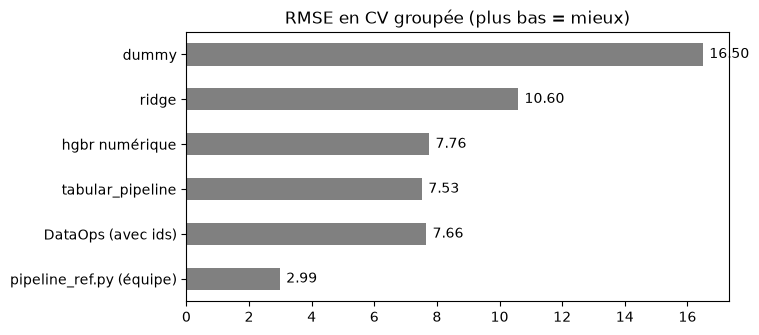

In [12]:
summary = pd.Series({
    "dummy": cv_scores(dummy, X).rmse.mean(),
    "ridge": s_ridge.rmse.mean(),
    "hgbr numérique": s_hgbr.rmse.mean(),
    "tabular_pipeline": res5["tabular_pipeline, tout X_full"].mean(),
    "DataOps (avec ids)": res6["TV + HGBR avec Index + patient_id"].mean(),
    "pipeline_ref.py (équipe)": 2.9875,
}, name="RMSE CV groupée")
ax = summary.plot.barh(color="grey", figsize=(7, 3.5), title="RMSE en CV groupée (plus bas = mieux)")
ax.invert_yaxis()
for i, v in enumerate(summary):
    ax.text(v + 0.2, i, f"{v:.2f}", va="center")
summary.round(3)

**Q7.1 — Quel changement a apporté la plus grosse amélioration ? Lequel n'a rien apporté ?**

| Changement | Effet sur le RMSE CV |
| --- | --- |
| Ridge → HGBR (changement de modèle) | 10.60 → 7.76, **le plus gros gain** |
| Ajout de `rater_id` (catégorielles) | 7.76 → 7.52 |
| Garder les NaN plutôt qu'imputer | ≈ −0.04 |
| `gene` + `cohort` | aucun effet |
| CV groupée | aucun gain : elle rend le score honnête (+0.1 sur Ridge) |

In [13]:
oof = np.zeros(len(y))
for tr_, te_ in cv_splits:
    m = clone(tabular_pipeline(HistGradientBoostingRegressor(random_state=0))).fit(X_full.iloc[tr_], y.iloc[tr_])
    oof[te_] = m.predict(X_full.iloc[te_])
v = visits.assign(err=np.abs(y - oof), duree=visits.age - visits.age_at_diagnosis,
                  off_manquant=visits.off.isna(), on_manquant=visits.on.isna())
worst = v.nlargest(int(len(v) * 0.02), "err")
cols = ["off_manquant", "on_manquant", "duree", "age", "ledd", "time_since_intake_on",
        "time_since_intake_off", "target"]
print(pd.DataFrame({"2 % pires visites": worst[cols].mean(), "toutes": v[cols].mean()}).round(2))
print("\ncohorte A :", round((worst.cohort == "A").mean(), 2), "vs", round((v.cohort == "A").mean(), 2))
print("\nerreur moyenne par durée de maladie (ans)")
print(v.groupby(pd.cut(v.duree, [-1, 2, 5, 10, 15, 50]), observed=True).err.mean().round(2))

                       2 % pires visites  toutes
off_manquant                        0.56    0.42
on_manquant                         0.16    0.30
duree                               7.07    5.85
age                                63.76   62.56
ledd                              680.52  637.90
time_since_intake_on                1.97    1.96
time_since_intake_off              13.74   14.20
target                             57.45   37.47

cohorte A : 0.93 vs 0.89

erreur moyenne par durée de maladie (ans)
duree
(-1, 2]     4.80
(2, 5]      5.64
(5, 10]     6.25
(10, 15]    6.76
(15, 50]    7.63
Name: err, dtype: float64


**Q7.2 — Sur les visites les plus mal prédites, qu'ont-elles en commun ?**

Sur les 2 % de pires erreurs (modèle `tabular_pipeline`, prédictions hors pli) :

- `off` manquant dans ≈ 57 % des cas, contre 42 % en moyenne : sans mesure OFF, le modèle doit deviner à partir du seul ON ;
- vrai OFF élevé (58 contre 37 en moyenne) : maladie avancée ;
- durée de maladie plus longue (≈ 7.2 ans contre 5.9) ; l'erreur moyenne monte régulièrement avec la durée, de 4.8 (< 2 ans) à 7.6 (> 15 ans) ;
- pas d'effet net de la cohorte (≈ 94 % A contre 89 %), ni des délais depuis la prise.

**Q7.3 — D'après CONTEXT.md, quel problème de modélisation n'a pas encore été traité ? Quelle variable construire ensuite ?**

Le workbook n'a traité que **les valeurs manquantes**. Restent :

- **la progression temporelle** : chaque visite est prédite seule, sans regarder les autres visites du patient. Prochaine variable : l'historique patient (scores aux visites précédentes et suivantes, tendance de OFF/ON en fonction de l'âge par patient). C'est ce que fait `src/exp_patient_features.py` (7.55 → 4.64).
- **le moment de la prise du traitement** : `time_since_intake_*` a une importance quasi nulle, car l'effet de la lévodopa n'est pas linéaire (absorption rapide puis déclin). Prochaine variable : un ON ramené à un équivalent OFF selon le délai depuis la prise.

`src/pipeline_ref.py` combine les deux, plus une correction du biais par évaluateur, et descend à 2.99 en CV (2.926 sur Kaggle).